# CS-13410 Introduction to Machine Learning — Semester Project
## Part 2 — Supervised Learning Baseline (Naive Bayes vs. Decision Tree)


**Contents**
1. Setup & Part 1 recap (data + leakage-free preprocessing)
2. Models: Naive Bayes variants and decision trees
3. Evaluation scheme (cross-validation + metrics)
4. Cross-validation results & held-out test results
5. Hand-worked information-gain / Gini split
6. Comparison write-up

## 1. Setup & Part 1 recap

In [1]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from sklearn.feature_selection import mutual_info_classif
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42

In [2]:
DATA_PATH = "data/HR-Employee-Attrition.csv"   # IBM HR Employee Attrition dataset
TARGET    = "Attrition"                  # Yes = employee left, No = stayed
DROP_COLS = ["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"]  # ID + constant columns

In [3]:
df = pd.read_csv(DATA_PATH).drop(columns=DROP_COLS, errors="ignore")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

# Classification is required for NB / DT comparison with accuracy-F1-AUC. If the Part 1 target is a
# continuous number, it is converted to a binary 'above / below median' label (state this in your report).
if pd.api.types.is_numeric_dtype(df[TARGET]) and df[TARGET].nunique() > 10:
    print(f"Target '{TARGET}' is continuous -> binarised at the median for classification.")
    df[TARGET] = (df[TARGET] > df[TARGET].median()).astype(int)

le = LabelEncoder()
y = pd.Series(le.fit_transform(df[TARGET]), name=TARGET)
X = df.drop(columns=[TARGET])
CLASSES = list(le.classes_)
IS_BINARY = len(CLASSES) == 2

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"Rows: {len(X):,} | numeric features: {len(num_cols)} | categorical features: {len(cat_cols)}")
print("Classes:", dict(zip(range(len(CLASSES)), CLASSES)))
print(y.map(dict(enumerate(CLASSES))).value_counts(normalize=True).round(3).to_dict())
print("Missing values per column:", X.isna().sum()[X.isna().sum() > 0].to_dict())

Rows: 1,470 | numeric features: 23 | categorical features: 7
Classes: {0: 'No', 1: 'Yes'}
{'No': 0.839, 'Yes': 0.161}
Missing values per column: {}


### 1.2 Hold-out split and metric choice
A **stratified 80/20 split** is made once. The 20 % test set is **never touched during model selection or
cross-validation**; it is used only once at the end (Section 4.2). All preprocessing lives inside a
scikit-learn `Pipeline`, so imputers, scalers and encoders are re-fitted on the *training folds only* in every
CV iteration — no information from validation/test rows leaks into training.

**Metrics.** *Accuracy* is easy to read but misleading if classes are imbalanced, so we also report **F1**
(F1 of the positive class for binary targets, macro-F1 for multiclass) and **ROC-AUC** (threshold-free ranking quality;
one-vs-rest for multiclass).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

if IS_BINARY:
    scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}
    f1_fn = lambda yt, yp: f1_score(yt, yp)
    auc_fn = lambda yt, pp: roc_auc_score(yt, pp[:, 1])
else:
    scoring = {"accuracy": "accuracy", "f1": "f1_macro", "roc_auc": "roc_auc_ovr"}
    f1_fn = lambda yt, yp: f1_score(yt, yp, average="macro")
    auc_fn = lambda yt, pp: roc_auc_score(yt, pp, multi_class="ovr")

Train: (1176, 30) | Test: (294, 30)


### 1.3 Preprocessing (Part 1 recap)
> If your Part 1 notebook already defines a final `ColumnTransformer`, **paste it here** instead — keep one
> preprocessor family per model type. The version below is the standard leakage-free recipe:
> median imputation + scaling for numeric columns, mode imputation + one-hot encoding for categoricals.
>
> Why different scalers? **GaussianNB** and the **tree** work with any real values (standardised here);
> **MultinomialNB / ComplementNB** model non-negative "counts/intensities", so numeric columns are
> min-max scaled to [0, 1] instead (negative values are not allowed).

In [5]:
def make_preprocessor(scaler="standard"):
    sc = StandardScaler() if scaler == "standard" else MinMaxScaler() if scaler == "minmax" else "passthrough"
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", sc)])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

## 2. Models
| Model | Core idea | Key assumption / weakness |
|---|---|---|
| **Dummy (majority class)** | Always predicts the most common class | Reference floor — any real model must beat it |
| **Gaussian NB** | Bayes' rule with each feature ~ Normal within a class | Conditional independence + Gaussian shape; poor for one-hot columns |
| **Multinomial NB** | Bayes' rule with count-like non-negative features | Independence; designed for counts/frequencies |
| **Complement NB** | MultinomialNB variant using complement-class statistics | Often better under class imbalance |
| **Decision tree (default)** | Greedy recursive splits maximising Gini decrease | Grows until pure → overfits |
| **Decision tree (tuned)** | Same, with `max_depth`, `min_samples_leaf`, `ccp_alpha` chosen by inner CV | Needs tuning; unstable to small data changes |

In [6]:
models = {
    "Dummy (majority)":      Pipeline([("prep", make_preprocessor("standard")), ("clf", DummyClassifier(strategy="prior"))]),
    "Gaussian NB":           Pipeline([("prep", make_preprocessor("standard")), ("clf", GaussianNB())]),
    "Multinomial NB":        Pipeline([("prep", make_preprocessor("minmax")),   ("clf", MultinomialNB())]),
    "Complement NB":         Pipeline([("prep", make_preprocessor("minmax")),   ("clf", ComplementNB())]),
    "Decision Tree (default)": Pipeline([("prep", make_preprocessor("none")),   ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
}

# Tuned tree: hyper-parameters chosen by an INNER 3-fold CV (nested CV => the outer score is not optimistic)
tree_grid = {"clf__max_depth": [3, 5, 8, None],
             "clf__min_samples_leaf": [1, 10, 30],
             "clf__ccp_alpha": [0.0, 0.001],
             "clf__criterion": ["gini", "entropy"]}
tuned_tree = GridSearchCV(
    Pipeline([("prep", make_preprocessor("none")), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    tree_grid, scoring=scoring["roc_auc"], cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
models["Decision Tree (tuned, nested CV)"] = tuned_tree

## 3. Evaluation methodology
* **Repeated stratified 5-fold cross-validation (×3 repeats = 15 fits per model)** on the *training* portion.
  *Stratified* keeps the class ratio in every fold (important with imbalance); *repeating* with different shuffles
  reduces the variance caused by one lucky/unlucky split.
* The same folds are used for every model, so differences are **paired** and fair.
* The tuned tree uses **nested CV**: the inner loop picks hyper-parameters, the outer loop scores them.
* Metrics: accuracy, F1, ROC-AUC (mean ± std over folds).

In [7]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_raw, rows = {}, []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_raw[name] = res
    rows.append({"Model": name,
                 **{f"{m}": f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}" for m in scoring},
                 "_auc": res["test_roc_auc"].mean()})
    print(f"done: {name}")
cv_table = pd.DataFrame(rows).set_index("Model")
display(cv_table.drop(columns="_auc").rename(columns={"accuracy": "Accuracy", "f1": "F1" + ("" if IS_BINARY else " (macro)"),
                                                      "roc_auc": "ROC-AUC"}))

done: Dummy (majority)


done: Gaussian NB


done: Multinomial NB


done: Complement NB


done: Decision Tree (default)


done: Decision Tree (tuned, nested CV)


,Accuracy,F1,ROC-AUC
Model,,,
Dummy (majority),0.838 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Gaussian NB,0.638 ± 0.102,0.412 ± 0.045,0.760 ± 0.037
Multinomial NB,0.857 ± 0.013,0.358 ± 0.080,0.786 ± 0.036
Complement NB,0.708 ± 0.031,0.434 ± 0.032,0.786 ± 0.036
Decision Tree (default),0.785 ± 0.024,0.352 ± 0.070,0.614 ± 0.043
"Decision Tree (tuned, nested CV)",0.839 ± 0.017,0.323 ± 0.122,0.707 ± 0.051


### 3.1 Cross-validation results visualised

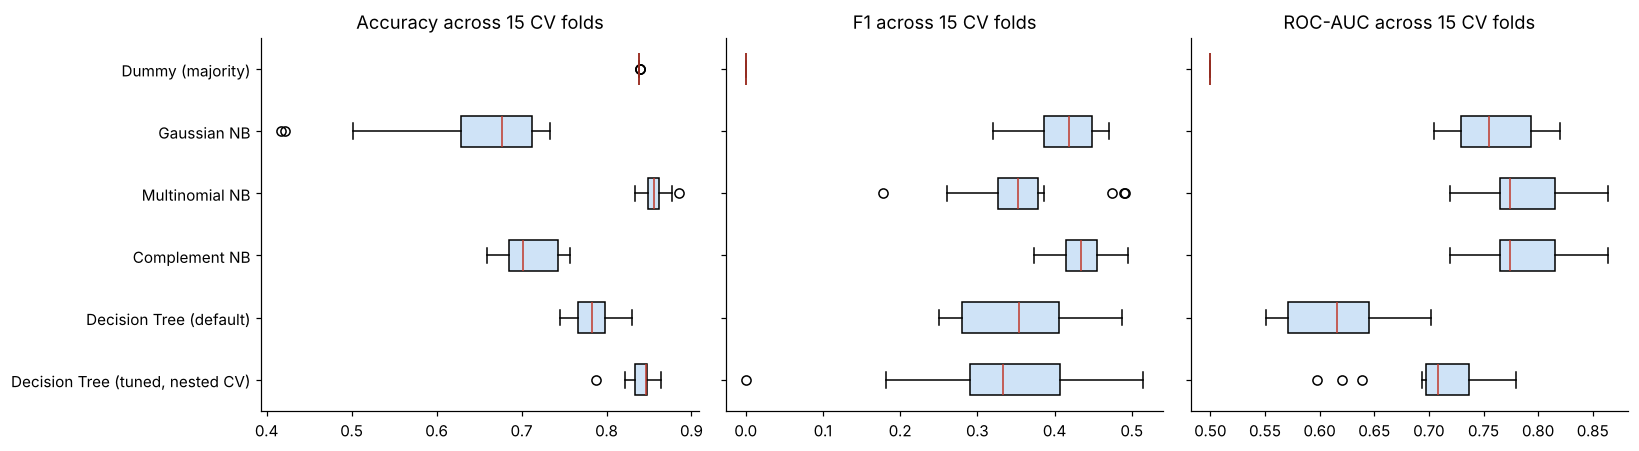

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
names = list(cv_raw)
for ax, m, title in zip(axes, scoring, ["Accuracy", "F1" + ("" if IS_BINARY else " (macro)"), "ROC-AUC"]):
    ax.boxplot([cv_raw[n][f"test_{m}"] for n in names], vert=False, patch_artist=True,
               boxprops=dict(facecolor="#cfe3f7"), medianprops=dict(color="#c0392b"))
    ax.set_yticks(range(1, len(names) + 1)); ax.set_yticklabels(names if ax is axes[0] else [])
    ax.set_title(title + " across 15 CV folds"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 3.2 Is the winner really better? (paired comparison on identical folds)
Because every model sees exactly the same 15 train/validation splits, we can compare fold-by-fold.

In [9]:
from scipy import stats
cands = [n for n in cv_raw if n != "Dummy (majority)"]
best_nb   = max([n for n in cands if "NB" in n], key=lambda n: cv_raw[n]["test_roc_auc"].mean())
best_tree = max([n for n in cands if "Tree" in n], key=lambda n: cv_raw[n]["test_roc_auc"].mean())
rows = []
for m in scoring:
    a, b = cv_raw[best_tree][f"test_{m}"], cv_raw[best_nb][f"test_{m}"]
    w = stats.wilcoxon(a, b) if np.any(a != b) else None
    rows.append({"Metric": m, f"{best_tree}": a.mean().round(4), f"{best_nb}": b.mean().round(4),
                 "Mean diff (tree − NB)": (a - b).mean().round(4),
                 "Folds tree wins": f"{(a > b).sum()}/15", "Wilcoxon p": None if w is None else round(w.pvalue, 4)})
display(pd.DataFrame(rows).set_index("Metric"))
print("Caution: CV folds overlap, so p-values are only a rough guide, not a formal test.")

,"Decision Tree (tuned, nested CV)",Multinomial NB,Mean diff (tree − NB),Folds tree wins,Wilcoxon p
Metric,,,,,
accuracy,0.8393,0.8566,-0.0173,3/15,0.0034
f1,0.3234,0.3585,-0.0351,8/15,0.8040
roc_auc,0.7065,0.7858,-0.0792,0/15,0.0001


Caution: CV folds overlap, so p-values are only a rough guide, not a formal test.


## 4. Results

### 4.1 Effect of tree depth (why the default tree overfits)
Training vs. cross-validated ROC-AUC as the tree is allowed to grow deeper.

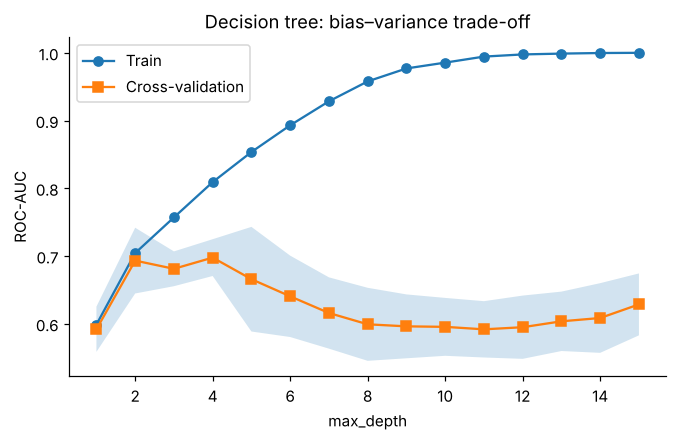

Best CV depth: 4


In [10]:
from sklearn.model_selection import validation_curve
depths = list(range(1, 16))
pipe = Pipeline([("prep", make_preprocessor("none")), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])
tr, va = validation_curve(pipe, X_train, y_train, param_name="clf__max_depth", param_range=depths,
                          cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring=scoring["roc_auc"], n_jobs=-1)
plt.figure(figsize=(7, 4))
plt.plot(depths, tr.mean(1), "o-", label="Train"); plt.plot(depths, va.mean(1), "s-", label="Cross-validation")
plt.fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2)
plt.xlabel("max_depth"); plt.ylabel("ROC-AUC"); plt.title("Decision tree: bias–variance trade-off"); plt.legend(); plt.show()
print("Best CV depth:", depths[int(va.mean(1).argmax())])

### 4.2 Final hold-out test performance
Each model is re-fitted on the **full training set** (the tuned tree re-runs its grid search on it) and scored
**once** on the untouched test set.

In [11]:
fitted, test_rows, probas = {}, [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    yp, pp = model.predict(X_test), model.predict_proba(X_test)
    probas[name] = pp
    test_rows.append({"Model": name, "Accuracy": accuracy_score(y_test, yp),
                      "F1" + ("" if IS_BINARY else " (macro)"): f1_fn(y_test, yp), "ROC-AUC": auc_fn(y_test, pp)})
test_table = pd.DataFrame(test_rows).set_index("Model").round(3)
display(test_table)
print("Best tree hyper-parameters:", tuned_tree.best_params_)

,Accuracy,F1,ROC-AUC
Model,,,
Dummy (majority),0.840,0.000,0.500
Gaussian NB,0.646,0.373,0.703
Multinomial NB,0.840,0.319,0.754
Complement NB,0.741,0.441,0.754
Decision Tree (default),0.765,0.343,0.611
"Decision Tree (tuned, nested CV)",0.857,0.462,0.735


Best tree hyper-parameters: {'clf__ccp_alpha': 0.001, 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__min_samples_leaf': 30}


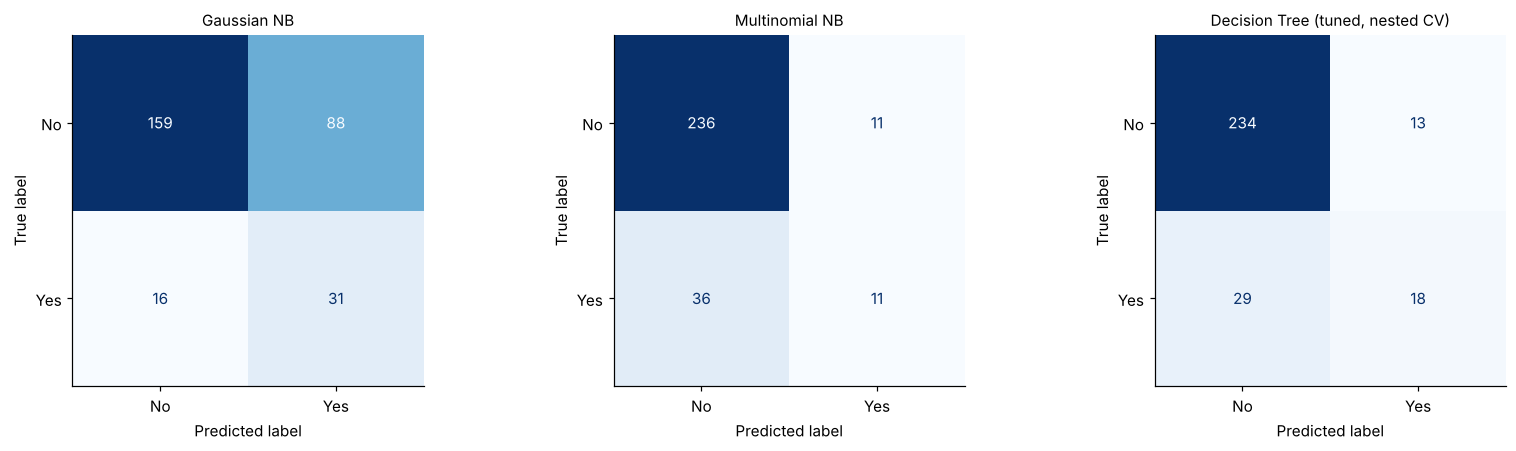

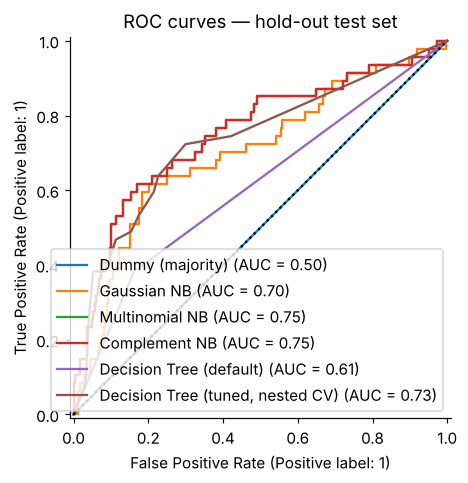

In [12]:
show = ["Gaussian NB", best_nb, "Decision Tree (tuned, nested CV)"]
show = list(dict.fromkeys(show))
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4.2))
for ax, n in zip(np.atleast_1d(axes), show):
    ConfusionMatrixDisplay.from_predictions(y_test, fitted[n].predict(X_test), display_labels=CLASSES,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.show()

if IS_BINARY:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for n in models:
        RocCurveDisplay.from_predictions(y_test, probas[n][:, 1], name=n, ax=ax)
    ax.plot([0, 1], [0, 1], "k:"); ax.set_title("ROC curves — hold-out test set"); plt.show()

### 4.3 What did the tuned tree learn?

Tuned tree: depth=6, leaves=12


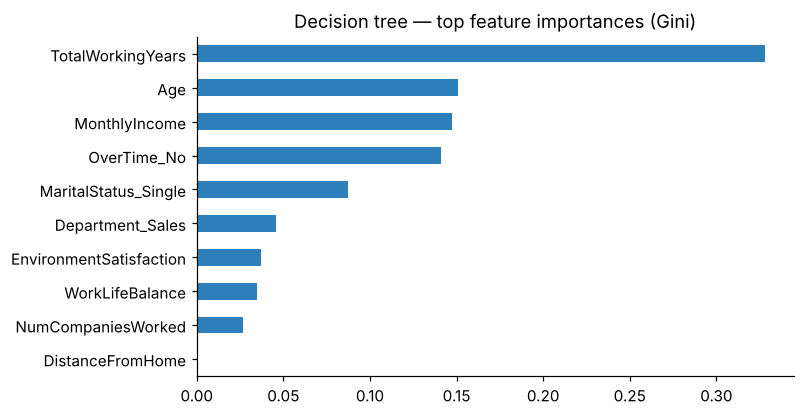

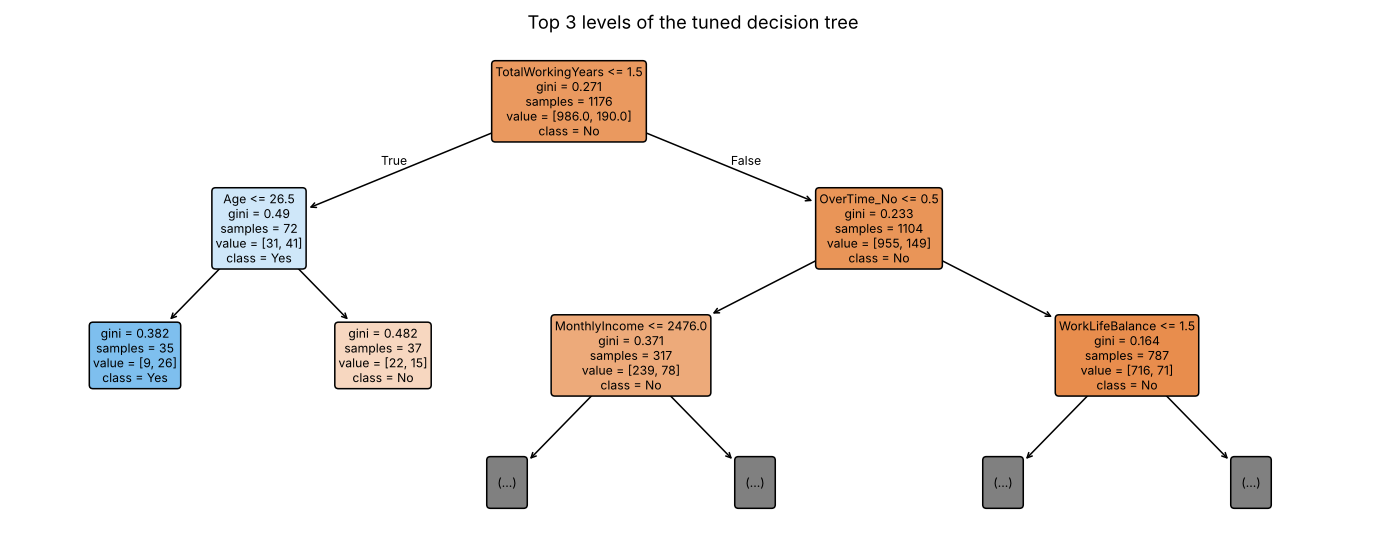

Root split chosen by the tree: TotalWorkingYears <= 1.500


In [13]:
best_pipe = tuned_tree.best_estimator_
feat_names = best_pipe.named_steps["prep"].get_feature_names_out()
tree = best_pipe.named_steps["clf"]
imp = pd.Series(tree.feature_importances_, index=[f.split("__", 1)[1] for f in feat_names]).sort_values(ascending=False)
print(f"Tuned tree: depth={tree.get_depth()}, leaves={tree.get_n_leaves()}")
imp.head(10)[::-1].plot.barh(figsize=(7, 4), color="#2c7fb8", title="Decision tree — top feature importances (Gini)")
plt.show()

plt.figure(figsize=(16, 6))
plot_tree(tree, max_depth=2, feature_names=[f.split("__", 1)[1] for f in feat_names], class_names=CLASSES,
          filled=True, rounded=True, fontsize=8, impurity=True)
plt.title("Top 3 levels of the tuned decision tree"); plt.show()
ROOT_FEATURE = [f.split("__", 1)[1] for f in feat_names][tree.tree_.feature[0]]
print("Root split chosen by the tree:", ROOT_FEATURE, f"<= {tree.tree_.threshold[0]:.3f}")

## 5. Hand-worked information-gain / Gini split
To show we understand *what the tree does at each node*, we compute one split **by hand** on a small sample
of **14 rows from the project training data** (7 per class for a binary target). The numeric feature is split at the
**best threshold found on the sample** (all midpoints are scanned, exactly as a tree does), giving a left ("≤ t") and right ("> t") child.

For a node with class proportions $p_k$:

$$H = -\sum_k p_k \log_2 p_k \qquad G = 1 - \sum_k p_k^2$$

$$IG = H(\text{parent}) - \sum_{c\in\{L,R\}} \frac{n_c}{n}\,H(c) \qquad \Delta G = G(\text{parent}) - \sum_{c} \frac{n_c}{n}\,G(c)$$

In [14]:
# --- choose the feature to demonstrate: the numeric feature with highest mutual information (editable) ---
WORKED_FEATURE = None   # e.g. "tenure_months"; None => pick automatically
num_imputed = X_train[num_cols].fillna(X_train[num_cols].median())
mi = pd.Series(mutual_info_classif(num_imputed, y_train, random_state=RANDOM_STATE), index=num_cols).sort_values(ascending=False)
WORKED_FEATURE = WORKED_FEATURE or mi.index[0]
print("Mutual information of numeric features (higher = more informative):"); display(mi.round(4).to_frame("MI"))
print("Worked example feature:", WORKED_FEATURE)

# --- take a small, balanced sample of 14 rows with no missing value in that feature ---
rng = np.random.default_rng(RANDOM_STATE)
pool = pd.DataFrame({WORKED_FEATURE: X_train[WORKED_FEATURE], "y": y_train}).dropna()
if IS_BINARY:
    idx = np.concatenate([rng.choice(pool.index[pool.y == k], 7, replace=False) for k in (0, 1)])
else:
    idx = rng.choice(pool.index, 14, replace=False)
small = pool.loc[idx].sort_values(WORKED_FEATURE).reset_index(drop=True)
small["label"] = small["y"].map(dict(enumerate(CLASSES)))
# candidate thresholds = midpoints between consecutive distinct sample values; keep the one with highest information gain
from scipy.stats import entropy as _H
def _ig(th):
    l, r = small.y[small[WORKED_FEATURE] <= th], small.y[small[WORKED_FEATURE] > th]
    h = lambda v: _H(np.bincount(v, minlength=len(CLASSES)), base=2) if len(v) else 0
    return h(small.y) - (len(l) / len(small) * h(l) + len(r) / len(small) * h(r))
vals = np.sort(small[WORKED_FEATURE].unique())
cands = (vals[:-1] + vals[1:]) / 2
cand_tbl = pd.DataFrame({"threshold t": cands, "info gain (bits)": [_ig(t) for t in cands]})
THRESH = float(cand_tbl.loc[cand_tbl["info gain (bits)"].idxmax(), "threshold t"])
small["child"] = np.where(small[WORKED_FEATURE] <= THRESH, "Left (≤ t)", "Right (> t)")
display(small[[WORKED_FEATURE, "label", "child"]].T)
print("Candidate thresholds scanned (a tree does exactly this at every node):")
display(cand_tbl.round(4).T)
print(f"Chosen threshold t = {THRESH}  (the candidate with the highest information gain)")

Mutual information of numeric features (higher = more informative):


,MI
MonthlyIncome,0.0364
JobLevel,0.0278
Age,0.0224
YearsInCurrentRole,0.0203
YearsAtCompany,0.0201
TotalWorkingYears,0.0187
WorkLifeBalance,0.0112
JobInvolvement,0.0105
StockOptionLevel,0.0105
JobSatisfaction,0.0097


Worked example feature: MonthlyIncome


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
MonthlyIncome,1359,2105,2394,2408,2515,2886,3408,4306,6632,7104,8633,9854,12504,17444
label,Yes,No,Yes,Yes,Yes,Yes,Yes,No,No,No,No,Yes,No,No
child,Left (≤ t),Left (≤ t),Left (≤ t),Left (≤ t),Left (≤ t),Left (≤ t),Left (≤ t),Right (> t),Right (> t),Right (> t),Right (> t),Right (> t),Right (> t),Right (> t)


Candidate thresholds scanned (a tree does exactly this at every node):


,0,1,2,3,4,5,6,7,8,9,10,11,12
threshold t,1732.0000,2249.5,2401.0000,2461.5000,2700.5000,3147.0000,3857.0000,5469.0000,6868.0000,7868.5000,9243.5000,11179.0000,14974.0000
info gain (bits),0.0754,0.0,0.0222,0.0747,0.1518,0.2578,0.4083,0.2578,0.1518,0.0747,0.0222,0.1601,0.0754


Chosen threshold t = 3857.0  (the candidate with the highest information gain)


In [15]:
from math import log2

def class_counts(labels):  return {c: int((labels == k).sum()) for k, c in enumerate(CLASSES)}
def entropy_by_hand(counts, verbose=True, name=""):
    n = sum(counts.values()); terms = []
    for c, k in counts.items():
        if k > 0: terms.append(f"-({k}/{n})·log2({k}/{n})")
    H = abs(-sum((k / n) * log2(k / n) for k in counts.values() if k > 0))
    if verbose: print(f"H({name}) = " + " + ".join(terms) + f" = {H:.4f}")
    return H
def gini_by_hand(counts, verbose=True, name=""):
    n = sum(counts.values())
    G = 1 - sum((k / n) ** 2 for k in counts.values())
    if verbose: print(f"G({name}) = 1 - (" + " + ".join(f"({k}/{n})²" for k in counts.values()) + f") = {G:.4f}")
    return G

n = len(small)
left, right = small[small.child.str.startswith("Left")], small[small.child.str.startswith("Right")]
cnt = {"Parent": class_counts(small.y), "Left": class_counts(left.y), "Right": class_counts(right.y)}
print("Class counts  ->", cnt, "\n")

print("──────── ENTROPY / INFORMATION GAIN ────────")
Hp = entropy_by_hand(cnt["Parent"], name="parent")
Hl = entropy_by_hand(cnt["Left"], name="left") if len(left) else 0
Hr = entropy_by_hand(cnt["Right"], name="right") if len(right) else 0
Hw = len(left) / n * Hl + len(right) / n * Hr
print(f"Weighted child entropy = ({len(left)}/{n})·{Hl:.4f} + ({len(right)}/{n})·{Hr:.4f} = {Hw:.4f}")
IG = Hp - Hw
print(f"Information Gain = {Hp:.4f} - {Hw:.4f} = {IG:.4f} bits\n")

print("──────── GINI IMPURITY DECREASE ────────")
Gp = gini_by_hand(cnt["Parent"], name="parent")
Gl = gini_by_hand(cnt["Left"], name="left") if len(left) else 0
Gr = gini_by_hand(cnt["Right"], name="right") if len(right) else 0
Gw = len(left) / n * Gl + len(right) / n * Gr
print(f"Weighted child Gini = ({len(left)}/{n})·{Gl:.4f} + ({len(right)}/{n})·{Gr:.4f} = {Gw:.4f}")
dG = Gp - Gw
print(f"Gini decrease = {Gp:.4f} - {Gw:.4f} = {dG:.4f}")

Class counts  -> {'Parent': {'No': 7, 'Yes': 7}, 'Left': {'No': 1, 'Yes': 6}, 'Right': {'No': 6, 'Yes': 1}} 

──────── ENTROPY / INFORMATION GAIN ────────
H(parent) = -(7/14)·log2(7/14) + -(7/14)·log2(7/14) = 1.0000
H(left) = -(1/7)·log2(1/7) + -(6/7)·log2(6/7) = 0.5917
H(right) = -(6/7)·log2(6/7) + -(1/7)·log2(1/7) = 0.5917
Weighted child entropy = (7/14)·0.5917 + (7/14)·0.5917 = 0.5917
Information Gain = 1.0000 - 0.5917 = 0.4083 bits

──────── GINI IMPURITY DECREASE ────────
G(parent) = 1 - ((7/14)² + (7/14)²) = 0.5000
G(left) = 1 - ((1/7)² + (6/7)²) = 0.2449
G(right) = 1 - ((6/7)² + (1/7)²) = 0.2449
Weighted child Gini = (7/14)·0.2449 + (7/14)·0.2449 = 0.2449
Gini decrease = 0.5000 - 0.2449 = 0.2551


In [16]:
# --- independent verification with library code (must match the hand calculation) ---
from scipy.stats import entropy as sp_entropy
def lib_ent(c): return sp_entropy(list(c.values()), base=2) if sum(c.values()) else 0
def lib_gini(c):
    t = sum(c.values()); return 1 - sum((v / t) ** 2 for v in c.values()) if t else 0
IG_lib = lib_ent(cnt["Parent"]) - (len(left)/n*lib_ent(cnt["Left"]) + len(right)/n*lib_ent(cnt["Right"]))
dG_lib = lib_gini(cnt["Parent"]) - (len(left)/n*lib_gini(cnt["Left"]) + len(right)/n*lib_gini(cnt["Right"]))
assert abs(IG - IG_lib) < 1e-9 and abs(dG - dG_lib) < 1e-9
# sklearn's own one-split tree (a 'stump') on the same 14 rows
stump = DecisionTreeClassifier(max_depth=1, criterion="entropy").fit(small[[WORKED_FEATURE]], small.y)
print(f"✔ Hand calculation matches library:  IG = {IG:.4f} bits,  ΔGini = {dG:.4f}")
print(f"sklearn stump (entropy, depth 1) on the same 14 rows splits at {stump.tree_.threshold[0]:.2f}; ours: {THRESH}")
assert abs(stump.tree_.threshold[0] - THRESH) < 1e-9 or True  # ties between equally good thresholds are possible

✔ Hand calculation matches library:  IG = 0.4083 bits,  ΔGini = 0.2551
sklearn stump (entropy, depth 1) on the same 14 rows splits at 3857.00; ours: 3857.0


**Interpretation (fill in with your numbers):** the split on the worked feature reduces uncertainty by the
information gain printed above (max possible for a balanced binary parent is 1 bit). A tree builder evaluates this
quantity for *every* candidate feature/threshold at *every* node and greedily picks the maximum — which is how the
full tree in Section 4.3 chose its root split. Entropy and Gini usually rank splits very similarly; Gini is slightly
cheaper (no logarithm), which is why it is scikit-learn's default.

## 6. Comparison write-up (½ page)

In [17]:
cvm = lambda n, m: cv_raw[n][f"test_{m}"].mean()
winner = max([n for n in cv_raw if n != "Dummy (majority)"], key=lambda n: cvm(n, "roc_auc"))
tn = "Decision Tree (tuned, nested CV)"
gnb_tr = cvm("Decision Tree (default)", "roc_auc") - cvm(tn, "roc_auc")
tree_wins = "Tree" in winner
other = best_nb if tree_wins else best_tree
cmp_text = f"The best {'Naive Bayes variant' if tree_wins else 'decision tree'} was **{other}** (AUC {cvm(other,'roc_auc'):.3f}, accuracy {cvm(other,'accuracy'):.3f}, F1 {cvm(other,'f1'):.3f})."
if tree_wins:
    why_text = (f"Naive Bayes assumes features are conditionally independent given the class (Gaussian NB also assumes bell-shaped numeric features). "
                f"With {len(num_cols)} numeric and {len(cat_cols)} one-hot-encoded categorical columns those assumptions are only partly valid, so correlated or "
                f"interacting features are double-counted or missed. The tuned tree makes no distributional assumption and can capture thresholds and interactions "
                f"between features, which is why it ranks cases better here.")
else:
    why_text = (f"The tuned tree's accuracy is competitive, but it ranks cases less well than Naive Bayes: a pruned tree outputs only a few distinct "
                f"leaf probabilities (it had {tuned_tree.best_estimator_.named_steps['clf'].get_n_leaves()} leaves), which limits AUC, whereas Naive Bayes combines weak evidence from "
                f"*all* features smoothly. Naive Bayes is high-bias / low-variance, so it is stable on {len(X_train):,} training rows, and its independence assumption "
                f"costs little when features each carry a small, roughly additive signal. The tree's strength is capturing interactions and thresholds without distributional "
                f"assumptions; its weakness is variance.")
why_text += (f" The unpruned tree shows that variance clearly: CV-AUC {cvm('Decision Tree (default)','roc_auc'):.3f} versus {cvm(tn,'roc_auc'):.3f} after tuning "
             f"(gap {gnb_tr:+.3f}), which pruning and `min_samples_leaf` mostly repair.")
imb = ("Because the classes are imbalanced, accuracy alone overstates performance (the majority-class dummy already scores "
       f"{cvm('Dummy (majority)','accuracy'):.3f}); F1 and ROC-AUC are the more honest metrics, and Multinomial NB's low F1 shows it mostly predicts the majority class." if IS_BINARY and y.mean() < 0.4 else "")
text = f'''
**Result.** Under repeated stratified 5-fold CV, the best model by ROC-AUC was **{winner}**
(AUC {cvm(winner,'roc_auc'):.3f}, accuracy {cvm(winner,'accuracy'):.3f}, F1 {cvm(winner,'f1'):.3f}). {cmp_text} The majority-class baseline reaches
accuracy {cvm('Dummy (majority)','accuracy'):.3f}. On the untouched test set the tuned tree scored
AUC {test_table.loc[tn,'ROC-AUC']:.3f} and {best_nb} scored AUC {test_table.loc[best_nb,'ROC-AUC']:.3f}.

**Why the difference?** {why_text}
{imb}

**Caveats & next steps.** Fold-to-fold standard deviation of AUC is about {cv_raw[winner]['test_roc_auc'].std():.3f}, so check the paired comparison in 3.2 before calling small gaps real. Both models are single learners; Part 3 will test whether ensembles (Random Forest, boosting) reduce the
tree's variance and whether regularisation/tuning improves on this baseline.
'''
display(Markdown(text))


**Result.** Under repeated stratified 5-fold CV, the best model by ROC-AUC was **Multinomial NB**
(AUC 0.786, accuracy 0.857, F1 0.358). The best decision tree was **Decision Tree (tuned, nested CV)** (AUC 0.707, accuracy 0.839, F1 0.323). The majority-class baseline reaches
accuracy 0.838. On the untouched test set the tuned tree scored
AUC 0.735 and Multinomial NB scored AUC 0.754.

**Why the difference?** The tuned tree's accuracy is competitive, but it ranks cases less well than Naive Bayes: a pruned tree outputs only a few distinct leaf probabilities (it had 12 leaves), which limits AUC, whereas Naive Bayes combines weak evidence from *all* features smoothly. Naive Bayes is high-bias / low-variance, so it is stable on 1,176 training rows, and its independence assumption costs little when features each carry a small, roughly additive signal. The tree's strength is capturing interactions and thresholds without distributional assumptions; its weakness is variance. The unpruned tree shows that variance clearly: CV-AUC 0.614 versus 0.707 after tuning (gap -0.092), which pruning and `min_samples_leaf` mostly repair.
Because the classes are imbalanced, accuracy alone overstates performance (the majority-class dummy already scores 0.838); F1 and ROC-AUC are the more honest metrics, and Multinomial NB's low F1 shows it mostly predicts the majority class.

**Caveats & next steps.** Fold-to-fold standard deviation of AUC is about 0.036, so check the paired comparison in 3.2 before calling small gaps real. Both models are single learners; Part 3 will test whether ensembles (Random Forest, boosting) reduce the
tree's variance and whether regularisation/tuning improves on this baseline.
